In [1]:
!pip install lazypredict -q

### 2. Carregamento e Inspeção do Dataset Processado

In [2]:
import pandas as pd

# Definindo o caminho do arquivo salvo
load_path = '/content/drive/MyDrive/- IRB/Vendaval-Base/dataset_v2_ML_ready.csv'

# Carregando o dataset
df_ml_loaded = pd.read_csv(load_path)

print(f"Dataset carregado com sucesso!")
print(f"Formato: {df_ml_loaded.shape}")
display(df_ml_loaded.head())

Dataset carregado com sucesso!
Formato: (37988, 34)


,station,time,ws_mean,ws_max,ws_std,ws_p90,sin_dir_mean,cos_dir_mean,msl_mean,msl_min,...,rajada_max_final_ms,latitude_x,longitude_x,station_lat,station_lon,categoria,rajada_max_corrigida,direcao_vento,latitude_y,longitude_y
0,A805,2000-01-01,6.296078,7.452370,0.593588,7.233298,0.739596,-0.659417,100868.335938,100646.3750,...,13.7899,-27.75,-53.75,-27.8544,-53.7911,0,14.002425,180.0,-27.85,-53.75
1,A805,2000-01-02,5.271899,6.899796,0.629632,6.116576,0.836034,-0.506626,100864.770833,100603.4375,...,12.1276,-27.75,-53.75,-27.8544,-53.7911,0,12.102600,180.0,-27.85,-53.75
2,A805,2000-01-03,4.650546,5.955361,1.055964,5.925378,0.746322,-0.582241,100737.343750,100430.6250,...,10.2608,-27.75,-53.75,-27.8544,-53.7911,0,10.181101,180.0,-27.85,-53.75
3,A805,2000-01-04,3.365570,4.957155,0.983495,4.504568,0.213188,-0.383864,100643.036458,100391.2500,...,8.2197,-27.75,-53.75,-27.8544,-53.7911,0,8.154307,180.0,-27.85,-53.75
4,A805,2000-01-05,2.664263,4.092182,0.939953,3.750594,0.017181,-0.051312,100701.078125,100541.1250,...,8.1747,-27.75,-53.75,-27.8544,-53.7911,0,8.270441,180.0,-27.85,-53.75


In [ ]:
# Remoção de NaN estruturais das features de lag (tp_lag1, tp_lag2, tp_roll3 têm NaN
# nas primeiras linhas de cada estação por construção — resultado do cálculo de lag/rolling)
lag_cols = ['tp_lag1', 'tp_lag2', 'tp_roll3']
n_before = len(df_ml_loaded)
df_ml_loaded = df_ml_loaded.dropna(subset=lag_cols).reset_index(drop=True)
n_after = len(df_ml_loaded)
print(f"Linhas removidas por NaN estrutural em {lag_cols}: {n_before - n_after}")
print(f"Dataset após limpeza: {df_ml_loaded.shape}")
print(f"NaN restantes nas colunas de lag: {df_ml_loaded[lag_cols].isna().sum().to_dict()}")

In [3]:
df_ml_loaded.columns

Index(['station', 'time', 'ws_mean', 'ws_max', 'ws_std', 'ws_p90',
       'sin_dir_mean', 'cos_dir_mean', 'msl_mean', 'msl_min', 'msl_range',
       't2m_mean', 't2m_max', 't2m_min', 't2m_range', 'rh_mean', 'rh_p10',
       'td_dep_mean', 'tp_sum', 'tp_max', 'd_msl', 'tp_lag1', 'tp_lag2',
       'tp_roll3', 'rajada_max_final_ms', 'latitude_x', 'longitude_x',
       'station_lat', 'station_lon', 'categoria', 'rajada_max_corrigida',
       'direcao_vento', 'latitude_y', 'longitude_y'],
      dtype='object')

In [4]:
# Excluindo colunas específicas para visualização da lista
vars_to_exclude = ['latitude_x', 'longitude_x']
remaining_columns = [col for col in df_ml_loaded.columns if col not in vars_to_exclude]

print(f"Colunas restantes ({len(remaining_columns)}):")
print(remaining_columns)

# Alternativamente, para criar um novo DataFrame sem essas colunas:
# df_subset = df_ml_loaded.drop(columns=['latitude_x', 'longitude_x'])

Colunas restantes (32):
['station', 'time', 'ws_mean', 'ws_max', 'ws_std', 'ws_p90', 'sin_dir_mean', 'cos_dir_mean', 'msl_mean', 'msl_min', 'msl_range', 't2m_mean', 't2m_max', 't2m_min', 't2m_range', 'rh_mean', 'rh_p10', 'td_dep_mean', 'tp_sum', 'tp_max', 'd_msl', 'tp_lag1', 'tp_lag2', 'tp_roll3', 'rajada_max_final_ms', 'station_lat', 'station_lon', 'categoria', 'rajada_max_corrigida', 'direcao_vento', 'latitude_y', 'longitude_y']


In [5]:
# Identificando a origem das variáveis
if 'origem_dados' in df_ml_loaded.columns:
    # Agrupando as colunas por origem
    # Note: assume-se que as colunas de dados estão no mesmo dataframe
    inmet_vars = df_ml_loaded[df_ml_loaded['origem_dados'] == 'INMET'].select_dtypes(include=['number']).columns.tolist()
    v2_vars = df_ml_loaded[df_ml_loaded['origem_dados'] == 'V2'].select_dtypes(include=['number']).columns.tolist()

    # Como o dataset é 'ML Ready', a coluna origem_dados pode estar codificada ou ser uma referência global
    # Vamos listar as colunas presentes no dataframe para conferência
    todas_colunas = df_ml_loaded.columns.tolist()

    print("--- Classificação das Variáveis ---")
    print(f"\nVariáveis totais no dataset: {len(todas_colunas)}")

    # Filtrando baseado em prefixos comuns ou na análise da coluna de origem se ela for categórica
    origens = df_ml_loaded['origem_dados'].unique()
    for origem in origens:
        cols = df_ml_loaded[df_ml_loaded['origem_dados'] == origem].columns.tolist()
        # Removendo metadados da contagem de variáveis de entrada
        cols = [c for c in cols if c not in ['time', 'station', 'origem_dados']]
        if cols:
            print(f"\nOrigem: {origem} ({len(cols)} variáveis)")
            print(", ".join(cols))
else:
    print("A coluna 'origem_dados' não foi encontrada para realizar a separação automática.")
    print("Colunas disponíveis:", df_ml_loaded.columns.tolist())

A coluna 'origem_dados' não foi encontrada para realizar a separação automática.
Colunas disponíveis: ['station', 'time', 'ws_mean', 'ws_max', 'ws_std', 'ws_p90', 'sin_dir_mean', 'cos_dir_mean', 'msl_mean', 'msl_min', 'msl_range', 't2m_mean', 't2m_max', 't2m_min', 't2m_range', 'rh_mean', 'rh_p10', 'td_dep_mean', 'tp_sum', 'tp_max', 'd_msl', 'tp_lag1', 'tp_lag2', 'tp_roll3', 'rajada_max_final_ms', 'latitude_x', 'longitude_x', 'station_lat', 'station_lon', 'categoria', 'rajada_max_corrigida', 'direcao_vento', 'latitude_y', 'longitude_y']


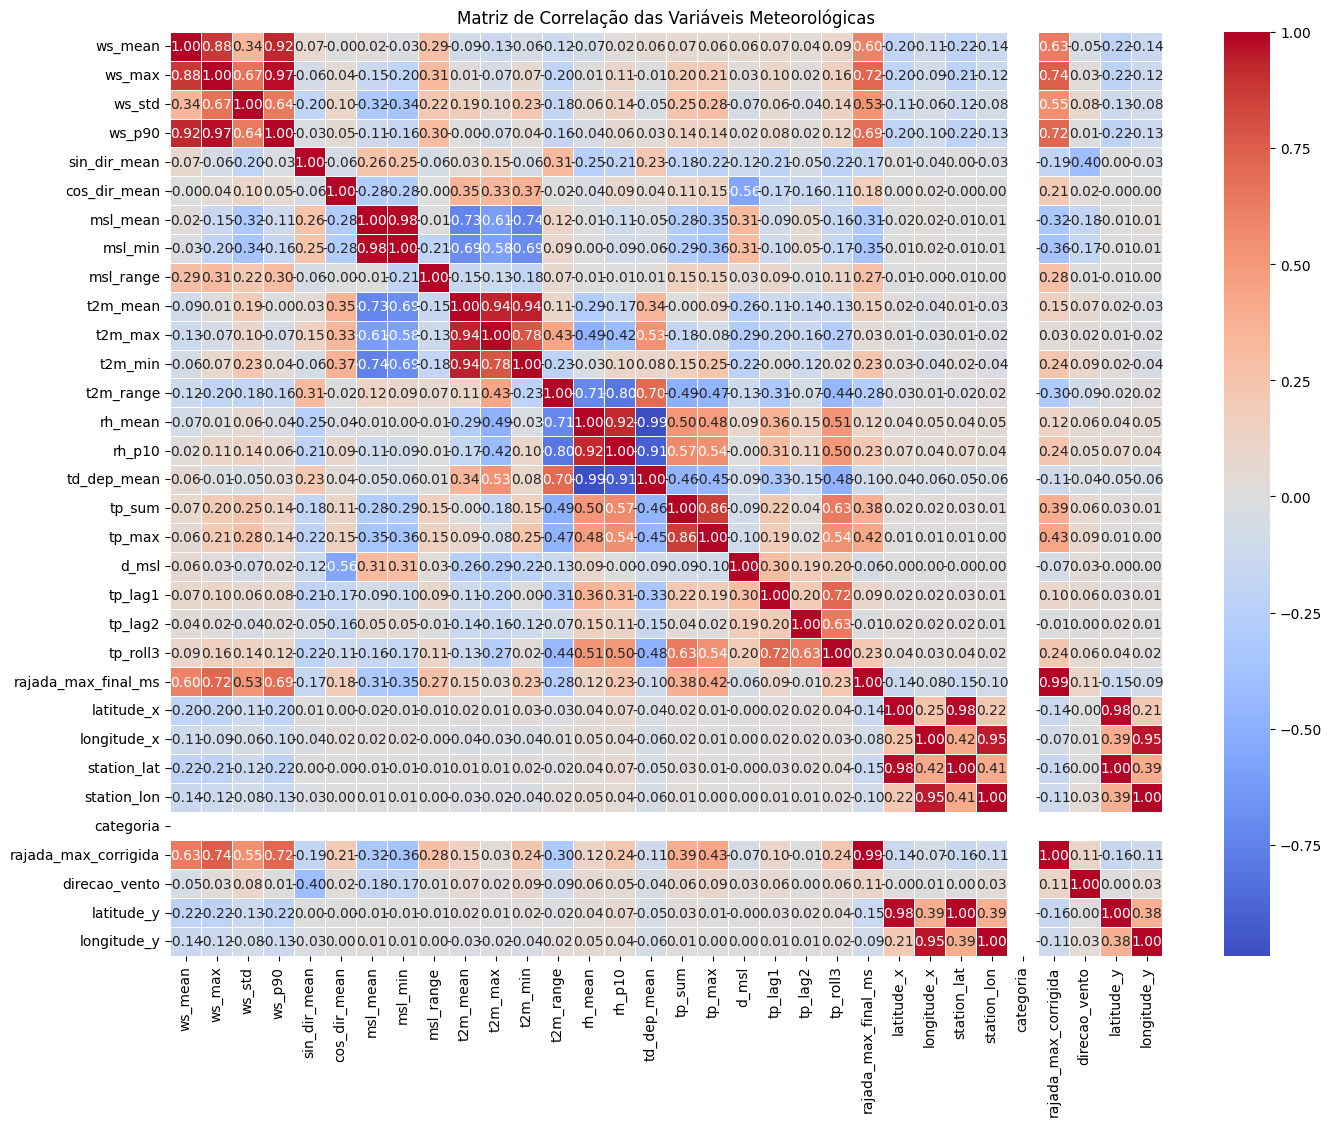

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculando a matriz de correlação apenas para colunas numéricas
corr_matrix = df_ml_loaded.select_dtypes(include=['number']).corr()

# Configurando o tamanho da figura
plt.figure(figsize=(16, 12))

# Criando o heatmap
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)

plt.title('Matriz de Correlação das Variáveis Meteorológicas')
plt.show()

In [7]:
# Focando na correlação com o alvo (rajada_max_corrigida)
target_corr = corr_matrix['rajada_max_corrigida'].sort_values(ascending=False)

print("--- Correlação com a Rajada Máxima Corrigida ---")
display(target_corr.to_frame())

--- Correlação com a Rajada Máxima Corrigida ---


,rajada_max_corrigida
rajada_max_corrigida,1.000000
rajada_max_final_ms,0.986088
ws_max,0.744693
ws_p90,0.715687
ws_mean,0.627460
ws_std,0.545054
tp_max,0.431196
tp_sum,0.388054
msl_range,0.283160
t2m_min,0.241467


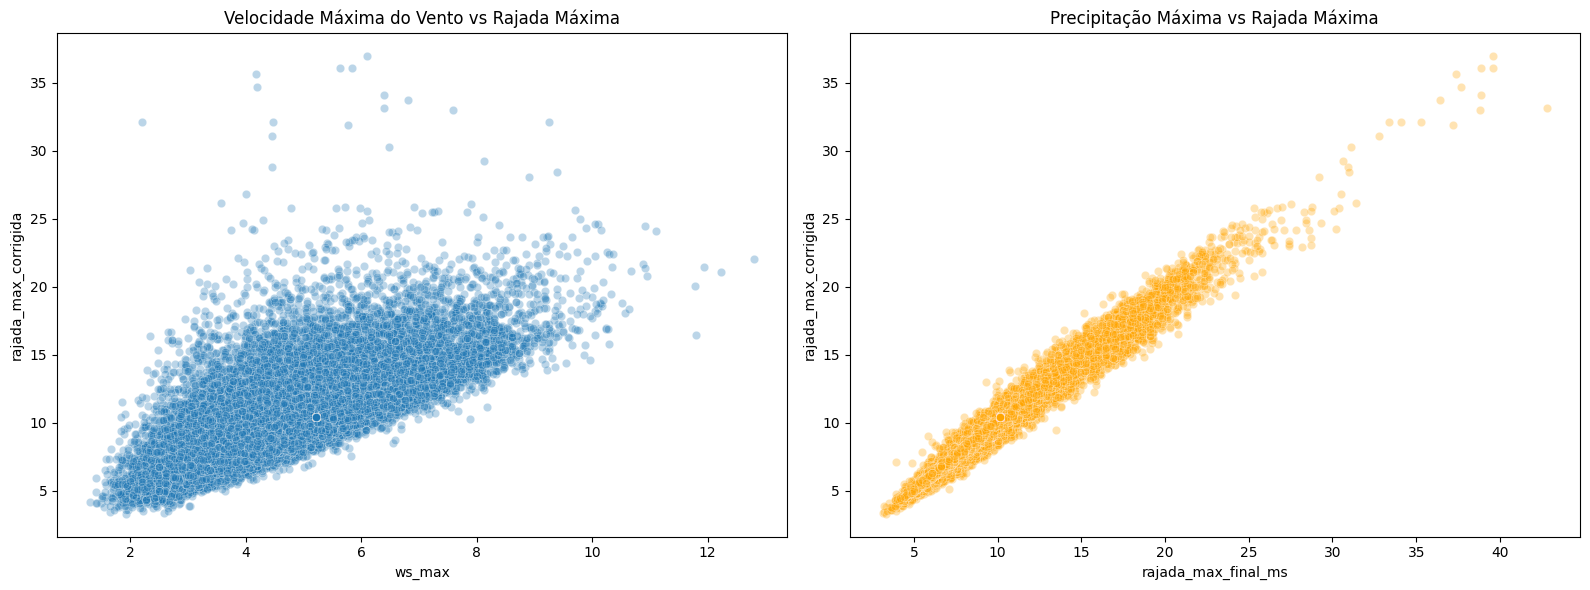

In [8]:
# Visualizando a relação entre as principais variáveis e o alvo
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Wind Speed Max vs Target
sns.scatterplot(data=df_ml_loaded, x='ws_max', y='rajada_max_corrigida', alpha=0.3, ax=axes[0])
axes[0].set_title('Velocidade Máxima do Vento vs Rajada Máxima')

# Total Precipitation vs Target
sns.scatterplot(data=df_ml_loaded, x='rajada_max_final_ms', y='rajada_max_corrigida', alpha=0.3, ax=axes[1], color='orange')
axes[1].set_title('Precipitação Máxima vs Rajada Máxima')

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# 1. Identificar estações únicas
all_stations = df_ml_loaded['station'].unique()
np.random.seed(42)  # reprodutibilidade

if len(all_stations) >= 4:
    test_station = np.random.choice(all_stations, 1, replace=False)[0]
    train_stations = [s for s in all_stations if s != test_station]
else:
    raise ValueError("Não há estações suficientes para a divisão 3+1 (treino+teste).")

print(f"Estações totais: {list(all_stations)}")
print(f"Estações de Treino: {list(train_stations)}")
print(f"Estação de Teste: {test_station}")

# 2. Dividir o DataFrame com base nas estações
df_train_spatial = df_ml_loaded[df_ml_loaded['station'].isin(train_stations)].copy()
df_test_spatial = df_ml_loaded[df_ml_loaded['station'] == test_station].copy()

print(f"\nShape do DataFrame de Treino Espacial: {df_train_spatial.shape}")
print(f"Shape do DataFrame de Teste Espacial: {df_test_spatial.shape}")


In [ ]:
def temporal_split_ratio(df_input, train_ratio=0.8, target_col='rajada_max_corrigida'):
    """
    Realiza um split temporal em um DataFrame com base em uma proporção.

    Args:
        df_input (pd.DataFrame): DataFrame de entrada com uma coluna 'time'.
        train_ratio (float): Proporção dos dados a serem usados para treino (e.g., 0.8 para 80%).
        target_col (str): Nome da coluna alvo (variável dependente).

    Returns:
        tuple: X_train, X_test, y_train, y_test
    """
    df_input = df_input.sort_values('time').reset_index(drop=True)

    # Calcular o índice para o split
    split_idx = int(len(df_input) * train_ratio)

    train_df = df_input.iloc[:split_idx]
    test_df = df_input.iloc[split_idx:]

    # Colunas removidas de X: target, leakage, metadados e categoria (sempre NaN)
    drop_cols_X = [target_col, 'rajada_max_final_ms', 'station', 'time', 'origem_dados', 'categoria']

    X_train = train_df.select_dtypes(include=['number']).drop(columns=[c for c in drop_cols_X if c in train_df.columns], errors='ignore')
    y_train = train_df[target_col]

    X_test = test_df.select_dtypes(include=['number']).drop(columns=[c for c in drop_cols_X if c in test_df.columns], errors='ignore')
    y_test = test_df[target_col]

    print(f"  - Treino: {len(y_train)} amostras (última data: {pd.to_datetime(train_df['time']).max().date()})")
    print(f"  - Teste:  {len(y_test)} amostras (primeira data: {pd.to_datetime(test_df['time']).min().date()})")

    return X_train, X_test, y_train, y_test

In [ ]:
# 3. Aplicar split temporal a cada subset espacial
#
# Arquitetura final de splits:
#   X_train_lazy    → 80% temporal de A805+A854+A856  (treino dos modelos)
#   X_val_lazy      → 20% temporal de A805+A854+A856  (screening via LazyPredict)
#   X_test_final    → 20% temporal de A853            (holdout duplo: novo espaço + novo tempo)
#   X_A853_temporal_train → 80% temporal de A853      (não usado — descartado para evitar leakage)

print("Aplicando split temporal (80/20) ao conjunto de treino espacial (A805, A854, A856):")
X_train_lazy, X_val_lazy, y_train_lazy, y_val_lazy = temporal_split_ratio(df_train_spatial, train_ratio=0.8)

print("\nAplicando split temporal (80/20) ao conjunto da estação holdout (A853):")
X_A853_temporal_train, X_test_final, y_A853_temporal_train, y_test_final = temporal_split_ratio(df_test_spatial, train_ratio=0.8)
print("  → X_A853_temporal_train descartado (não entra em treinamento nem avaliação)")
print("  → X_test_final é o holdout duplo (espacial + temporal)")

# --- Feature Engineering: Remoção de coordenadas duplicadas e direção crua ---
# latitude_x/y e longitude_x/y são duplicatas de station_lat/station_lon
columns_to_remove_fe = ['latitude_x', 'longitude_x', 'latitude_y', 'longitude_y', 'direcao_vento']

X_train_lazy = X_train_lazy.drop(columns=[c for c in columns_to_remove_fe if c in X_train_lazy.columns], errors='ignore')
X_val_lazy   = X_val_lazy.drop(columns=[c for c in columns_to_remove_fe if c in X_val_lazy.columns], errors='ignore')
X_test_final = X_test_final.drop(columns=[c for c in columns_to_remove_fe if c in X_test_final.columns], errors='ignore')

print(f"\nColunas removidas por feature engineering: {columns_to_remove_fe}")
print(f"\nDimensões finais:")
print(f"  X_train_lazy  : {X_train_lazy.shape}  ← treino dos modelos")
print(f"  X_val_lazy    : {X_val_lazy.shape}   ← screening LazyPredict (mesmo espaço, período recente)")
print(f"  X_test_final  : {X_test_final.shape}   ← holdout duplo (A853, período recente)")

assert X_train_lazy.shape[1] == X_val_lazy.shape[1] == X_test_final.shape[1], \
    "ERRO: número de features inconsistente entre os conjuntos!"
print("\n✓ Feature sets consistentes entre train/val/test")

In [12]:
import joblib
import os

save_data_path = '/content/drive/MyDrive/- IRB/Vendaval-Base/Data'
os.makedirs(save_data_path, exist_ok=True)

print(f"Salvando os datasets em: {save_data_path}")

for fname, obj in [
    ('X_train_lazy.joblib', X_train_lazy),
    ('y_train_lazy.joblib', y_train_lazy),
    ('X_val_lazy.joblib',   X_val_lazy),
    ('y_val_lazy.joblib',   y_val_lazy),
    ('X_test_final.joblib', X_test_final),
    ('y_test_final.joblib', y_test_final),
]:
    path = os.path.join(save_data_path, fname)
    joblib.dump(obj, path)
    print(f"  Salvo: {path}")

print("\nDatasets salvos com sucesso!")


Salvando os datasets em: /content/drive/MyDrive/- IRB/Vendaval-Base/Data
  Dataset X_train_lazy salvo em /content/drive/MyDrive/- IRB/Vendaval-Base/Data/X_train_lazy.joblib
  Dataset y_train_lazy salvo em /content/drive/MyDrive/- IRB/Vendaval-Base/Data/y_train_lazy.joblib
  Dataset X_test_lazy salvo em /content/drive/MyDrive/- IRB/Vendaval-Base/Data/X_test_lazy.joblib
  Dataset y_test_lazy salvo em /content/drive/MyDrive/- IRB/Vendaval-Base/Data/y_test_lazy.joblib

Datasets salvos com sucesso!


In [ ]:
# Verificação do feature set final usado no treinamento
# (definido em cell-11 após o split espacial+temporal — sem acesso a dados do conjunto de teste)
print("Features usadas no treinamento:")
print(list(X_train_lazy.columns))
print(f"\nTotal: {X_train_lazy.shape[1]} features, {X_train_lazy.shape[0]} amostras de treino")
print(f"\nNaN em X_train_lazy: {X_train_lazy.isna().sum().sum()}")
print(f"NaN em X_val_lazy:   {X_val_lazy.isna().sum().sum()}")
print(f"NaN em X_test_final: {X_test_final.isna().sum().sum()}")

### 4. Triagem de Algoritmos: Teste de Viabilidade por Consumo de RAM

In [14]:
!pip install psutil -q   # para capturar RAM disponível

import psutil
import numpy as np
import pandas as pd
import tracemalloc
import time
import warnings
import threading
from scipy.optimize import curve_fit
from sklearn.utils import all_estimators
from sklearn.exceptions import ConvergenceWarning
import gc

warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', category=UserWarning)

In [15]:
# Configurações
TAMANHOS_AMOSTRA = [500, 1000, 2000]   # menores = mais rápido, mas menos preciso
TIMEOUT_POR_MODELO = 60                # segundos
MARGEM_SEGURANCA = 0.8                 # usar no máximo 80% da RAM disponível

# Funções de medição (já conhecidas)
def measure_memory_peak(model_class, X, y, **kwargs):
    tracemalloc.start()
    try:
        model = model_class(**kwargs)
        model.fit(X, y)
        _, peak = tracemalloc.get_traced_memory()
        return peak / (1024 * 1024)
    except Exception:
        return None
    finally:
        tracemalloc.stop()

def run_with_timeout(func, timeout, *args, **kwargs):
    result = [None]
    error = [None]
    def target():
        try:
            result[0] = func(*args, **kwargs)
        except Exception as e:
            error[0] = e
    thread = threading.Thread(target=target)
    thread.start()
    thread.join(timeout)
    if thread.is_alive():
        raise TimeoutError(f"Timeout {timeout}s")
    if error[0]:
        raise error[0]
    return result[0]

def power_law(n, a, c):
    return a * (n ** c)

def extrapolate_memory(tamanhos, memorias, N_total):
    mask = ~np.isnan(memorias)
    n_obs = np.array(tamanhos)[mask]
    mem_obs = np.array(memorias)[mask]
    if len(n_obs) < 2:
        return np.nan, np.nan
    try:
        params, _ = curve_fit(power_law, n_obs, mem_obs, maxfev=2000)
        a, c = params
        return power_law(N_total, a, c), c
    except:
        slope = mem_obs[-1] / n_obs[-1] if len(mem_obs) > 0 else 0
        return slope * N_total, 1.0

In [ ]:
# RAM disponível (calculado após definição do dataset de treino, para usar N_TOTAL correto)
import psutil as _psutil
_mem = _psutil.virtual_memory()
ram_total_gb = _mem.total / (1024**3)
ram_disponivel_gb = _mem.available / (1024**3)
ram_limite_gb = ram_disponivel_gb * MARGEM_SEGURANCA
print(f"RAM total: {ram_total_gb:.1f} GB")
print(f"RAM disponível agora: {ram_disponivel_gb:.1f} GB")
print(f"Limite a ser usado (80%): {ram_limite_gb:.1f} GB")

# Feature space para teste de viabilidade — mesmo usado no treinamento real
X_viab = X_train_lazy.copy()
y_viab = y_train_lazy.copy()
N_TOTAL = len(X_viab)
print(f"\nX_viab: {X_viab.shape}, y_viab: {y_viab.shape}")


In [ ]:
# Listar todos os regressores
regressores = all_estimators(type_filter='regressor')
print(f"Total de regressores a testar: {len(regressores)}")

modelos_viaveis = []
modelos_falhos = []

for i, (name, RegressorClass) in enumerate(regressores):
    print(f"\n[{i+1}/{len(regressores)}] {name}...", end=" ", flush=True)

    # Parâmetros especiais para alguns modelos
    if name == 'GaussianProcessRegressor':
        kwargs = {'random_state': 42}
    elif name in ['SVR', 'NuSVR', 'KernelRidge']:
        kwargs = {'kernel': 'rbf', 'cache_size': 100}
    elif name in ['AdaBoostRegressor', 'GradientBoostingRegressor']:
        kwargs = {'random_state': 42}
    else:
        try:
            dummy = RegressorClass()
            kwargs = {'random_state': 42} if 'random_state' in dummy.get_params() else {}
        except:
            kwargs = {}

    tamanhos = []
    memorias = []
    inviavel = False
    motivo_falha = ""

    for n in TAMANHOS_AMOSTRA:
        if n > N_TOTAL:
            continue

        X_sample = X_viab.iloc[:n]
        y_sample = y_viab.iloc[:n]

        try:
            mem_mb = run_with_timeout(measure_memory_peak, TIMEOUT_POR_MODELO,
                                      RegressorClass, X_sample, y_sample, **kwargs)
            if mem_mb is None:
                motivo_falha = "Falhou (retornou None)"
                inviavel = True
                break
            tamanhos.append(n)
            memorias.append(mem_mb)
            print(f"{n}:{mem_mb:.0f}MB ", end="", flush=True)
        except TimeoutError:
            motivo_falha = "Timeout"
            inviavel = True
            break
        except MemoryError:
            motivo_falha = "MemoryError"
            inviavel = True
            break
        except Exception as e:
            motivo_falha = f"Erro: {str(e)[:30]}"
            inviavel = True
            break

    if inviavel or len(tamanhos) < 2:
        modelos_falhos.append({'Modelo': name, 'Motivo': motivo_falha})
        if not inviavel: print("dados insuficientes para extrapolação", end="")
        continue

    # Extrapolar para N_total
    mem_total_mb, expoente = extrapolate_memory(tamanhos, memorias, N_total=N_TOTAL)
    if np.isnan(mem_total_mb):
        modelos_falhos.append({'Modelo': name, 'Motivo': "Falha na extrapolação"})
        continue

    mem_total_gb = mem_total_mb / 1024

    if mem_total_gb <= ram_limite_gb:
        modelos_viaveis.append({
            'Modelo': name,
            'Memoria_estimada_GB': mem_total_gb,
            'Expoente': expoente,
            'Testado_em_amostras': tamanhos
        })
        print(f"=> VIÁVEL ({mem_total_gb:.2f} GB)")
    else:
        modelos_falhos.append({'Modelo': name, 'Motivo': f"Inviável (RAM: {mem_total_gb:.1f}GB)"})
        print(f"=> INVIÁVEL ({mem_total_gb:.2f} GB > {ram_limite_gb:.1f} GB)")

    gc.collect()

# DataFrames de resumo
df_viaveis = pd.DataFrame(modelos_viaveis).sort_values('Memoria_estimada_GB')
df_falhos = pd.DataFrame(modelos_falhos)

In [22]:
print("\n" + "="*70)
print(f"MODELOS QUE CABEM NA RAM DISPONÍVEL ({ram_limite_gb:.1f} GB para o dataset de {N_TOTAL} amostras)")
print("="*70)
if len(df_viaveis) == 0:
    print("Nenhum modelo é viável. Considere reduzir o dataset ou aumentar a RAM.")
else:
    print(df_viaveis[['Modelo', 'Memoria_estimada_GB', 'Expoente']].to_string(index=False))
    print(f"\nTotal de modelos viáveis: {len(df_viaveis)} de {len(regressores)}")

print("\n" + "="*70)
print("MODELOS QUE FALHARAM OU SÃO INVIÁVEIS")
print("="*70)
display(df_falhos.sort_values('Motivo'))


MODELOS QUE CABEM NA RAM DISPONÍVEL (8.9 GB para o dataset de 37988 amostras)
                       Modelo  Memoria_estimada_GB  Expoente
               DummyRegressor             0.000007  0.050210
          ExtraTreesRegressor             0.012112  0.980354
           ExtraTreeRegressor             0.012131  0.979378
        DecisionTreeRegressor             0.012142  0.979625
        RandomForestRegressor             0.012302  0.985653
             BaggingRegressor             0.014332  0.911114
HistGradientBoostingRegressor             0.023830  0.657459

Total de modelos viáveis: 7 de 55

MODELOS QUE FALHARAM OU SÃO INVIÁVEIS


,Modelo,Motivo
0,ARDRegression,Falhou (retornou None)
26,MultiTaskLasso,Falhou (retornou None)
27,MultiTaskLassoCV,Falhou (retornou None)
28,NuSVR,Falhou (retornou None)
29,OrthogonalMatchingPursuit,Falhou (retornou None)
30,OrthogonalMatchingPursuitCV,Falhou (retornou None)
31,PLSCanonical,Falhou (retornou None)
32,PLSRegression,Falhou (retornou None)
33,PassiveAggressiveRegressor,Falhou (retornou None)
34,PoissonRegressor,Falhou (retornou None)


In [ ]:
from lazypredict.Supervised import LazyRegressor
import warnings
import pandas as pd

warnings.filterwarnings('ignore')

# LazyPredict faz screening usando X_val_lazy (mesma distribuição espacial do treino,
# período temporal mais recente). O holdout final (X_test_final) fica reservado para
# o modelo selecionado — sem contaminação do processo de seleção.
reg = LazyRegressor(verbose=0, ignore_warnings=True, custom_metric=None, random_state=42)

print("Executando LazyRegressor benchmark (train → val, mesmo espaço espacial)...")
models, predictions = reg.fit(X_train_lazy, X_val_lazy, y_train_lazy, y_val_lazy)

# Filtrar para modelos viáveis em RAM
exclude_models = [
    'GaussianProcessRegressor', 'CCA', 'IsotonicRegression', 'KernelRidge',
    'MultiOutputRegressor', 'MultiTaskElasticNet', 'MultiTaskElasticNetCV',
    'MultiTaskLasso', 'MultiTaskLassoCV', 'PLSCanonical', 'RegressorChain',
    'StackingRegressor', 'VotingRegressor'
]
viable_model_names = df_viaveis['Modelo'].tolist()
final_filter = [m for m in viable_model_names if m not in exclude_models]

models_filtered = models[models.index.isin(final_filter)]

print("\nResultados LazyPredict (filtrado por viabilidade de RAM — avaliado em X_val_lazy):")
display(models_filtered)

### 6. Diagnóstico Visual da Distribuição Espaço-Temporal

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# --- Código de preparação dos dados para df_plotting ---
# Reconstruct df_plotting for visualization
df_plotting = df_ml_loaded.copy()

# Add spatial_group
df_plotting['spatial_group'] = df_plotting['station'].apply(lambda x: 'Test Station' if x == test_station else 'Train Stations')

# Add split_category based on temporal splits
df_plotting['split_category'] = None

# Identify rows belonging to each temporal split and assign category
# Need to determine the temporal split points for df_train_spatial and df_test_spatial
# These were implicitly determined by the temporal_split_ratio function using a 0.8 ratio

# Re-calculate split limits for robustness (as the original dfs were modified in subsequent steps)
df_train_spatial_sorted = df_train_spatial.sort_values('time').reset_index(drop=True)
split_idx_train = int(len(df_train_spatial_sorted) * 0.8)
# Get the time value at the split index for df_train_spatial
limit_date_train = pd.to_datetime(df_train_spatial_sorted.iloc[split_idx_train]['time'])

df_test_spatial_sorted = df_test_spatial.sort_values('time').reset_index(drop=True)
split_idx_test = int(len(df_test_spatial_sorted) * 0.8)
# Get the time value at the split index for df_test_spatial
limit_date_test = pd.to_datetime(df_test_spatial_sorted.iloc[split_idx_test]['time'])


# Assign categories based on spatial and temporal conditions
for station_name in df_plotting['station'].unique():
    station_mask = df_plotting['station'] == station_name

    if station_name == test_station:
        # This is the test station, apply its temporal split logic
        temporal_mask_train = pd.to_datetime(df_plotting['time']) <= limit_date_test
        temporal_mask_holdout = pd.to_datetime(df_plotting['time']) > limit_date_test

        df_plotting.loc[station_mask & temporal_mask_train, 'split_category'] = 'Spatial Test - Temporal Train'
        df_plotting.loc[station_mask & temporal_mask_holdout, 'split_category'] = 'Spatial Test - Temporal Holdout'
    else:
        # These are train stations, apply their temporal split logic
        temporal_mask_train = pd.to_datetime(df_plotting['time']) <= limit_date_train
        temporal_mask_val = pd.to_datetime(df_plotting['time']) > limit_date_train

        df_plotting.loc[station_mask & temporal_mask_train, 'split_category'] = 'Spatial Train - Temporal Train'
        df_plotting.loc[station_mask & temporal_mask_val, 'split_category'] = 'Spatial Train - Temporal Val'

# Ensure 'time' column is datetime type for plotting
df_plotting['time'] = pd.to_datetime(df_plotting['time'])
# --- Fim do código de preparação dos dados para df_plotting ---


# Visualização
fig, axes = plt.subplots(1, 2, figsize=(18, 8))  # 1 linha, 2 colunas

# ========== SUBPLOT 1: Mapa espacial ==========
unique_stations_df = df_plotting.drop_duplicates(subset=['station'])
sns.scatterplot(data=unique_stations_df, x='station_lon', y='station_lat', hue='spatial_group',
                s=200, ax=axes[0], palette={'Train Stations': 'blue', 'Test Station': 'red'}, marker='o')
for i, row in unique_stations_df.iterrows():
    axes[0].text(row['station_lon'] + 0.01, row['station_lat'], row['station'], fontsize=10, ha='left', va='center')
axes[0].set_title('Divisão Espacial das Estações (Treino vs Teste)')
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].grid(True)

# Legenda do subplot 1: abaixo, centralizada
axes[0].legend(title='Grupo Espacial', loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)


# ========== SUBPLOT 2: Distribuição temporal ==========
station_order = sorted(df_plotting['station'].unique())
category_colors = {
    'Spatial Train - Temporal Train': 'skyblue',
    'Spatial Train - Temporal Val': 'darkblue',
    'Spatial Test - Temporal Train': 'lightcoral',
    'Spatial Test - Temporal Holdout': 'firebrick'
}

# Criar legenda manual
legend_handles = []
for category, color in category_colors.items():
    legend_handles.append(plt.Rectangle((0, 0), 1, 1, fc=color, ec="none", label=category))

for station_name in station_order:
    station_data = df_plotting[df_plotting['station'] == station_name].sort_values('time')
    for category in station_data['split_category'].unique():
        if category:
            subset = station_data[station_data['split_category'] == category]
            if not subset.empty:
                min_time = subset['time'].min()
                max_time = subset['time'].max()
                axes[1].hlines(y=station_name, xmin=min_time, xmax=max_time,
                               color=category_colors[category], linewidth=10)

axes[1].set_title('Divisão Temporal por Estação e Categoria de Split')
axes[1].set_xlabel('Data')
axes[1].set_ylabel('Estação')
axes[1].set_yticks(station_order)
axes[1].grid(True, axis='x', linestyle='--', alpha=0.7)

# Legenda do subplot 2: abaixo, centralizada
axes[1].legend(handles=legend_handles, title='Tipo de Split', loc='upper center',
               bbox_to_anchor=(0.5, -0.15), ncol=2)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.utils import all_estimators as _all_estimators
reg_dict = {name: cls for name, cls in _all_estimators(type_filter='regressor')}

import numpy as np
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Seleciona o melhor modelo da lista viável (menor RMSE no val set)
best_model_name = models_filtered.sort_values('RMSE').index[0]
RegressorClass = reg_dict[best_model_name]

print(f"Melhor modelo viável: {best_model_name}")
print(f"Instanciando e treinando em X_train_lazy...")

kwargs = {'random_state': 42} if 'random_state' in RegressorClass().get_params() else {}
model = RegressorClass(**kwargs)
model.fit(X_train_lazy, y_train_lazy)

# Avaliação no holdout duplo (A853 — novo espaço + novo tempo)
y_pred_best = model.predict(X_test_final)

rmse = np.sqrt(mean_squared_error(y_test_final, y_pred_best))
r2   = r2_score(y_test_final, y_pred_best)
mae  = mean_absolute_error(y_test_final, y_pred_best)

print(f"\nPerformance de {best_model_name} no holdout duplo (X_test_final — A853, período recente):")
print(f"  R²   : {r2:.4f}")
print(f"  RMSE : {rmse:.4f} m/s")
print(f"  MAE  : {mae:.4f} m/s")

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print(f"Scatter plot — {best_model_name} no holdout duplo (X_test_final):")

fig, ax = plt.subplots(1, 1, figsize=(10, 6))

rmse_val = np.sqrt(mean_squared_error(y_test_final, y_pred_best))

sns.scatterplot(x=y_test_final, y=y_pred_best, ax=ax, alpha=0.6)
ax.set_title(f'{best_model_name} — Holdout Duplo (A853, período recente)\nRMSE: {rmse_val:.2f} m/s')
ax.set_xlabel('Real (m/s)')
ax.set_ylabel('Predito (m/s)')

min_val = min(y_test_final.min(), y_pred_best.min())
max_val = max(y_test_final.max(), y_pred_best.max())
ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Predição ideal')
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Comparação LazyPredict: melhor modelo pelo RMSE no val set
best_model_name_lazy = models.sort_values('RMSE').index[0]
best_model_rmse_lazy = models.loc[best_model_name_lazy, 'RMSE']

print(f"Melhor modelo geral do LazyPredict: {best_model_name_lazy} (RMSE val: {best_model_rmse_lazy:.4f})")
print("Retreinando para plotar predições no holdout duplo (X_test_final)...")

RegressorClass_lazy = reg_dict[best_model_name_lazy]
kwargs_lazy = {'random_state': 42} if 'random_state' in RegressorClass_lazy().get_params() else {}
model_lazy = RegressorClass_lazy(**kwargs_lazy)
model_lazy.fit(X_train_lazy, y_train_lazy)
y_pred_best_lazy = model_lazy.predict(X_test_final)

rmse_final = np.sqrt(mean_squared_error(y_test_final, y_pred_best_lazy))

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.scatterplot(x=y_test_final, y=y_pred_best_lazy, ax=ax, alpha=0.6)
ax.set_title(f'{best_model_name_lazy} — Holdout Duplo (A853, período recente)\nRMSE: {rmse_final:.2f} m/s')
ax.set_xlabel('Real (m/s)')
ax.set_ylabel('Predito (m/s)')

min_val = min(y_test_final.min(), y_pred_best_lazy.min())
max_val = max(y_test_final.max(), y_pred_best_lazy.max())
ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Predição ideal')
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribuição de predições vs. valores reais no holdout duplo
plt.figure(figsize=(10, 6))
sns.histplot(y_test_final, kde=True, color='blue', label='Valores Reais (y_test_final)', stat='density', alpha=0.6)
sns.histplot(y_pred_best, kde=True, color='orange', label=f'Predições ({best_model_name})', stat='density', alpha=0.6)

plt.title(f'Distribuição das Predições vs. Valores Reais\n{best_model_name} — Holdout Duplo (A853, período recente)')
plt.xlabel('Rajada Máxima Corrigida (m/s)')
plt.ylabel('Densidade')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### 8. Avaliação do Melhor Estimador: Distribuição de Erros e Resíduos

In [ ]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Avaliação de extremos usando y_test_final e y_pred_best (holdout duplo)
percentis = [0.95, 0.975, 0.99]
thresholds = y_test_final.quantile(percentis)

print(f"Avaliação de extremos — {best_model_name}")
print(f"Conjunto: holdout duplo (A853, período recente, {len(y_test_final)} amostras)\n")

results_outliers = []

for p, thresh in zip(percentis, thresholds):
    mask = y_test_final >= thresh
    y_true_out = y_test_final[mask]
    y_pred_out = y_pred_best[mask]

    rmse = np.sqrt(mean_squared_error(y_true_out, y_pred_out))
    mae  = mean_absolute_error(y_true_out, y_pred_out)
    bias = np.mean(y_pred_out - y_true_out)

    results_outliers.append({
        'Percentil': p,
        'Limiar (m/s)': round(thresh, 2),
        'Amostras': len(y_true_out),
        'RMSE': round(rmse, 2),
        'MAE': round(mae, 2),
        'Bias (Erro Médio)': round(bias, 2)
    })

df_outliers = pd.DataFrame(results_outliers)
display(df_outliers)

plt.figure(figsize=(12, 6))
sns.scatterplot(x=y_test_final, y=y_pred_best, alpha=0.3, label='Dados Gerais')

for i, (p, thresh) in enumerate(zip(percentis, thresholds)):
    plt.axvline(thresh, color=f'C{i+1}', linestyle='--', label=f'P{int(p*100)} ({thresh:.1f} m/s)')

plt.plot([y_test_final.min(), y_test_final.max()],
         [y_test_final.min(), y_test_final.max()], 'r--', label='Ideal')
plt.title(f'Performance em Valores Extremos — {best_model_name}\nHoldout Duplo (A853, período recente)')
plt.xlabel('Real (m/s)')
plt.ylabel('Predito (m/s)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 9. Avaliação de Extremos
Nesta seção, analisamos a capacidade do modelo de prever valores nas caudas da distribuição (percentis 95, 97.5 e 99).